In [3]:
import tifffile
import os
import numpy as np
from data.data import _masks_folder_to_masks
video=tifffile.imread("/home/tristan/code/SINETRA/dataset/hydra_flow/0.2-50.0/111/video.tiff")


masks_original=_masks_folder_to_masks("/home/tristan/code/SINETRA/dataset/hydra_flow/0.2-50.0/111/tracks")


# SPAGHETTI TIME

In [2]:
from data import gaussian_ellipse_mask_from_labels
coords=[]
masks=[]
for track in masks_original:
    mask, coord = gaussian_ellipse_mask_from_labels(track)
    masks.append(mask)
    coords.append(coord)
masks=np.array(masks)




In [3]:
coords_per_label={}
tracks=[]
for frame, coord in enumerate(coords):
    for id, coordinates in coord.items():
        if id not in coords_per_label:
            coords_per_label[id] = []
        coords_per_label[id].append(coordinates)
        tracks.append([id, frame, coordinates[0], coordinates[1]])

# # coords_per_label_array=np.array([coords for coords in coords_per_label.values()])
# print(coords_per_label_array.shape)
# print(coords_per_label_array[:,0,:])

AttributeError: 'numpy.ndarray' object has no attribute 'items'

In [ ]:
masks=None

In [4]:
import napari
viewer=napari.Viewer()
viewer.add_image(video, name="video")
seg=napari.layers.Labels(np.array(masks_original).astype(np.int32), name="tracks")
tra=napari.layers.Tracks(np.array(tracks))
viewer.add_layer(seg)
viewer.add_layer(tra)

NameError: name 'tracks' is not defined

# SPAGHETTINET SIAMESE


In [ ]:
%load_ext autoreload
%autoreload 2

In [1]:
from data.data import SpagDataModule

data_module=SpagDataModule(
    root_folder="/home/tristan/code/SINETRA/dataset/springs_2d_simple/0.2-50.0",
    subfolders=["111", "222", "333"],
    batch_size=2,
    max_length_of_training_samples=200,
    max_length_of_validation_samples=200,
    max_length_of_testing_samples=200,
)

Found min and max values of images:  0 255


DefaultDataset: Preprocessing masks with distance transform: 100%|██████████| 20/20 [00:00<00:00, 234318.66it/s]

Found min and max values of images:  0 255


DefaultDataset: Preprocessing masks with distance transform: 100%|██████████| 20/20 [00:00<00:00, 665.69it/s]


Found min and max values of images:  0 255


DefaultDataset: Preprocessing masks with distance transform: 100%|██████████| 20/20 [00:00<00:00, 4129.67it/s]

######## Successfully loaded datasets ########
Root folder: /home/tristan/code/SINETRA/dataset/springs_2d_simple/0.2-50.0
Train dataset length: 20
Val dataset length: 20
Test dataset length: 20
###############################################


In [16]:
for batch in data_module.train_dataloader():

           x,y_spots,coords=batch

print(coords[:,0])

tensor([[  1.0000, 241.3889, 538.6111],
        [  1.0000, 247.9672, 539.2131]], dtype=torch.float64)


In [ ]:
from models.unet import SiameseUNet
from lightning import Trainer
from lightning.pytorch.loggers import TensorBoardLogger
model=SiameseUNet(in_channels=1, features=[64, 128, 256], feat_channels=32, spots_channels=1)
model.automatic_optimization = False
logger=TensorBoardLogger(
    save_dir=f"training_logs/first_try/",
    name=f"SiameseUNet"
)
        #save best val loss model checkpoint

trainer=Trainer(max_epochs=100, accelerator="cuda", logger=logger, log_every_n_steps=1)
trainer.fit(model, data_module)


/home/tristan/anaconda3/envs/newenv_byotrack/lib/python3.10/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /home/tristan/anaconda3/envs/newenv_byotrack/lib/pyt ...
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
You are using a CUDA device ('NVIDIA RTX 3500 Ada Generation Laptop GPU') that has Tensor Cores. To properly utilize them, 

┏━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name          ┃ Type            ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ loss_fn_spots │ MSELoss         │      0 │ train │     0 │
│ 1 │ model         │ SiameseUNetBase │ 14.3 M │ train │     0 │
└───┴───────────────┴─────────────────┴────────┴───────┴───────┘

Trainable params: 14.3 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 14.3 M                                                                                               
Total estimated model params size (MB): 57                                                                         
Modules in train mode: 85                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/home/tristan/anaconda3/envs/newenv_byotrack/lib/python3.10/site-packages/lightning/pytorch/utilities/_pytree.py:21
: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` 
instead.

/home/tristan/anaconda3/envs/newenv_byotrack/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data
_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing 
the value of the `num_workers` argument` to `num_workers=31` in the `DataLoader` to improve performance.

/home/tristan/anaconda3/envs/newenv_byotrack/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data
_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing
the value of the `num_workers` argument` to `num_workers=31` in the `DataLoader` to improve performance.

`Trainer.fit` stopped: `max_epochs=100` reached.


#test loss


In [ ]:
#test cosine_sim

import torch

e1=torch.tensor([[1,0], [0,1],[3,2]], dtype=torch.float32).unsqueeze(0) # shape (1,3,2)
e2=torch.tensor([[0,1], [-1,0],[1,0]], dtype=torch.float32).unsqueeze(1) # shape (3,1,2)
# compute euclidean distance between e1 and e2
euclidean_distance=torch.sqrt(torch.sum((e1-e2)**2, dim=-1))
print("euclidean distance", euclidean_distance)



euclidean distance tensor([[1.4142, 0.0000, 3.1623],
        [2.0000, 1.4142, 4.4721],
        [0.0000, 1.4142, 2.8284]])


In [ ]:
dist=torch.tensor([[10,3,5],[4,20,6],[7,8,30]], dtype=torch.float32)
print("dist", dist)
diag= torch.diag(dist)
print("diag", diag) 

remove_diag=torch.ones_like(dist) - torch.eye(dist.shape[0])


min_diag=torch.max(diag.unsqueeze(0), diag.unsqueeze(1))
#set diagonal to 0

loss_matrix=torch.maximum((min_diag-dist +1)*remove_diag,torch.zeros_like(dist))
print("loss_matrix", loss_matrix)

loss_value=torch.sum(loss_matrix)

print("loss_value", loss_value)


dist tensor([[10.,  3.,  5.],
        [ 4., 20.,  6.],
        [ 7.,  8., 30.]])
diag tensor([10., 20., 30.])
loss_matrix tensor([[ 0., 18., 26.],
        [17.,  0., 25.],
        [24., 23.,  0.]])
loss_value tensor(133.)


In [ ]:
import torch
t=torch.tensor([2,3,4,1,5])
t.sort()

torch.return_types.sort(
values=tensor([1, 2, 3, 4, 5]),
indices=tensor([3, 0, 1, 2, 4]))

# PREDICTION TIME

In [1]:
%load_ext autoreload
%autoreload 2

In [13]:
from data.data import SpagDataModule

data_module=SpagDataModule(
    root_folder="/home/tristan/code/SINETRA/dataset/hydra_flow/0.2-50.0",
    subfolders=[None, None, "111"],
    batch_size=1,
    max_length_of_training_samples=100,
    max_length_of_validation_samples=200,
    max_length_of_testing_samples=2,


)

Found min and max values of images:  0 255


DefaultDataset: Preprocessing masks with distance transform: 100%|██████████| 2/2 [00:00<00:00,  9.35it/s]

######## Successfully loaded datasets ########
Root folder: /home/tristan/code/SINETRA/dataset/hydra_flow/0.2-50.0
Train dataset length: N/A
Val dataset length: N/A
Test dataset length: 2
###############################################


In [3]:
from models.unet import FeatureUNet
model=FeatureUNet(in_channels=1, features=[64,128,256,512], feat_channels=64, spots_channels=1, feature_head_feats=256)

model.eval()
model.load_from_checkpoint("/mnt/helix/FeatureNet/training_logs/separate_train/FeatureUNet_64_1_hydra_flow/version_0/checkpoints/last.ckpt")

Model weights loaded from /mnt/helix/FeatureNet/training_logs/separate_train/FeatureUNet_64_1_hydra_flow/version_0/checkpoints/last.ckpt


Predicting:   0%|          | 0/2 [00:00<?, ?it/s]

Input shape: torch.Size([1024, 1024])
Output shape: torch.Size([1, 1, 1024, 1024]), Feature shape: torch.Size([1, 64, 1024, 1024])
spots_output shape: torch.Size([1, 1, 1024, 1024]), feat_output shape: torch.Size([1, 64, 1024, 1024])


Predicting:  50%|█████     | 1/2 [00:06<00:06,  6.63s/it]

Input shape: torch.Size([1024, 1024])
Output shape: torch.Size([1, 1, 1024, 1024]), Feature shape: torch.Size([1, 64, 1024, 1024])
spots_output shape: torch.Size([1, 1, 1024, 1024]), feat_output shape: torch.Size([1, 64, 1024, 1024])


Predicting: 100%|██████████| 2/2 [00:13<00:00,  6.66s/it]


heatmap shape torch.Size([1, 1, 1024, 1024])
features shape torch.Size([1, 64, 1024, 1024])


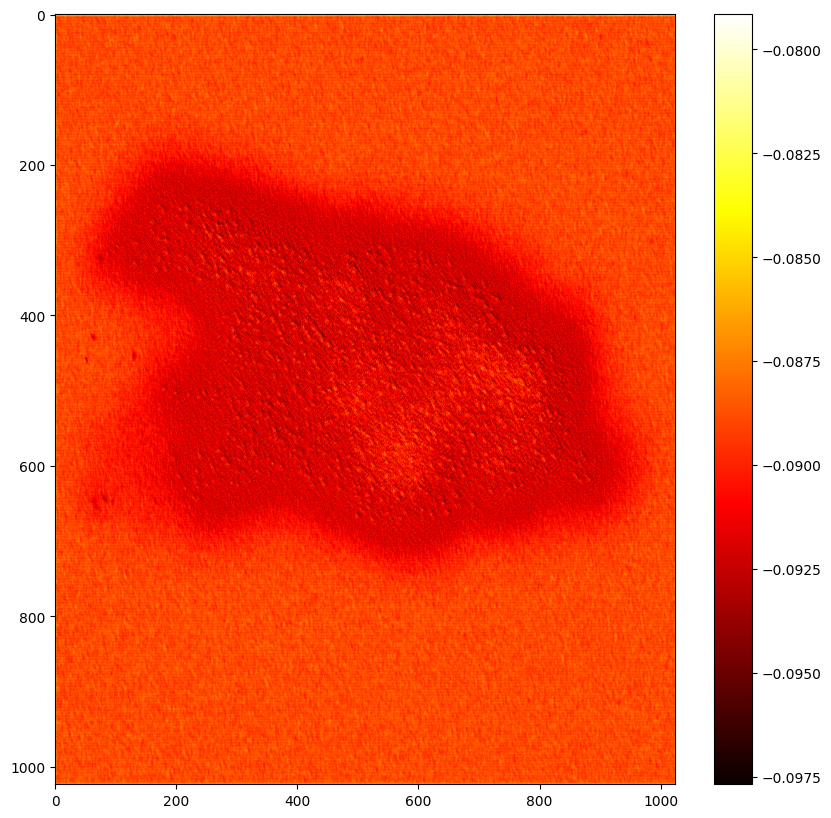

In [14]:
model.eval()
preds=model.predict(data_module, disable_tqdm=False, keep_pseudo_probs=True)
heatmap,feats=preds[0]

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 10))
plt.imshow(heatmap.squeeze(), cmap='hot', aspect='auto')
#add colorbar
plt.colorbar()
print("heatmap shape", heatmap.shape)
print("features shape", feats.shape)

In [8]:
# for i in range(feats.squeeze().shape[0]):
#     plt.figure(figsize=(5,5))
#     plt.imshow(feats.detach().squeeze()[i,:], cmap='hot', aspect='auto')
#     plt.title(f"Frame {i}")
#     plt.colorbar()
#     plt.show()

Values between 0.00 and 0.03: 0
Values between 0.03 and 0.06: 0
Values between 0.06 and 0.09: 0
Values between 0.09 and 0.12: 0
Values between 0.12 and 0.15: 0
Values between 0.15 and 0.18: 0
Values between 0.18 and 0.21: 0
Values between 0.21 and 0.24: 0
Values between 0.24 and 0.27: 0
Values between 0.27 and 0.30: 0
Values between 0.30 and 0.33: 0
Values between 0.33 and 0.36: 0
Values between 0.36 and 0.39: 0
Values between 0.39 and 0.42: 0
Values between 0.42 and 0.45: 0
Values between 0.45 and 0.48: 0
Values between 0.48 and 0.51: 0
Values between 0.51 and 0.54: 0
Values between 0.54 and 0.57: 0
Values between 0.57 and 0.60: 0
Values between 0.60 and 0.63: 0
Values between 0.63 and 0.66: 0
Values between 0.66 and 0.69: 0
Values between 0.69 and 0.72: 0
Values between 0.72 and 0.75: 0
Values between 0.75 and 0.78: 0
Values between 0.78 and 0.81: 0
Values between 0.81 and 0.84: 0
Values between 0.84 and 0.87: 0
Values between 0.87 and 0.90: 0
Values between 0.90 and 0.93: 0
Values b

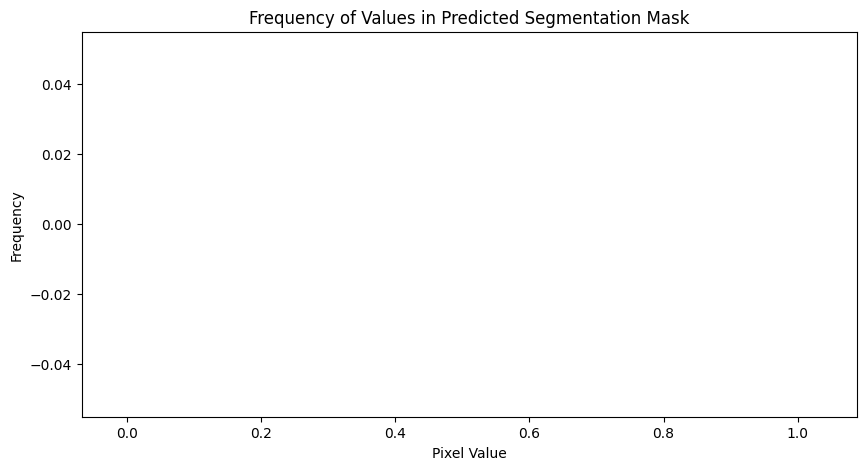

In [10]:
# show frequency of values in the predicted segmentation mask, every 0.02 from 0 to 1
import matplotlib.pyplot as plt
import numpy as np

pred_spots=pred_spots.squeeze().detach().cpu().numpy()
spacing=0.03
for value in np.arange(0, 1+spacing, spacing):
    count = np.sum((pred_spots >= value) & (pred_spots < value + spacing))
    print(f"Values between {value:.2f} and {value + spacing:.2f}: {count}" )
plt.figure(figsize=(10, 5))
plt.bar([value for value in np.arange(0, 1+spacing, spacing)], [np.sum((pred_spots >= value) & (pred_spots < value + spacing)) for value in np.arange(0, 1+spacing, spacing)], width=spacing)
plt.title('Frequency of Values in Predicted Segmentation Mask')
plt.xlabel('Pixel Value')
plt.ylabel('Frequency')
plt.show()

In [5]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 10))
plt.imshow(pred_spots, cmap='hot', aspect='auto')
plt.title('Predicted Segmentation Mask')
plt.xlabel('X Pixel')
plt.ylabel('Y Pixel')
plt.show()

NameError: name 'pred_spots' is not defined

<Figure size 1000x1000 with 0 Axes>

Number of detected peaks: 738
Number of ground truth peaks: 774


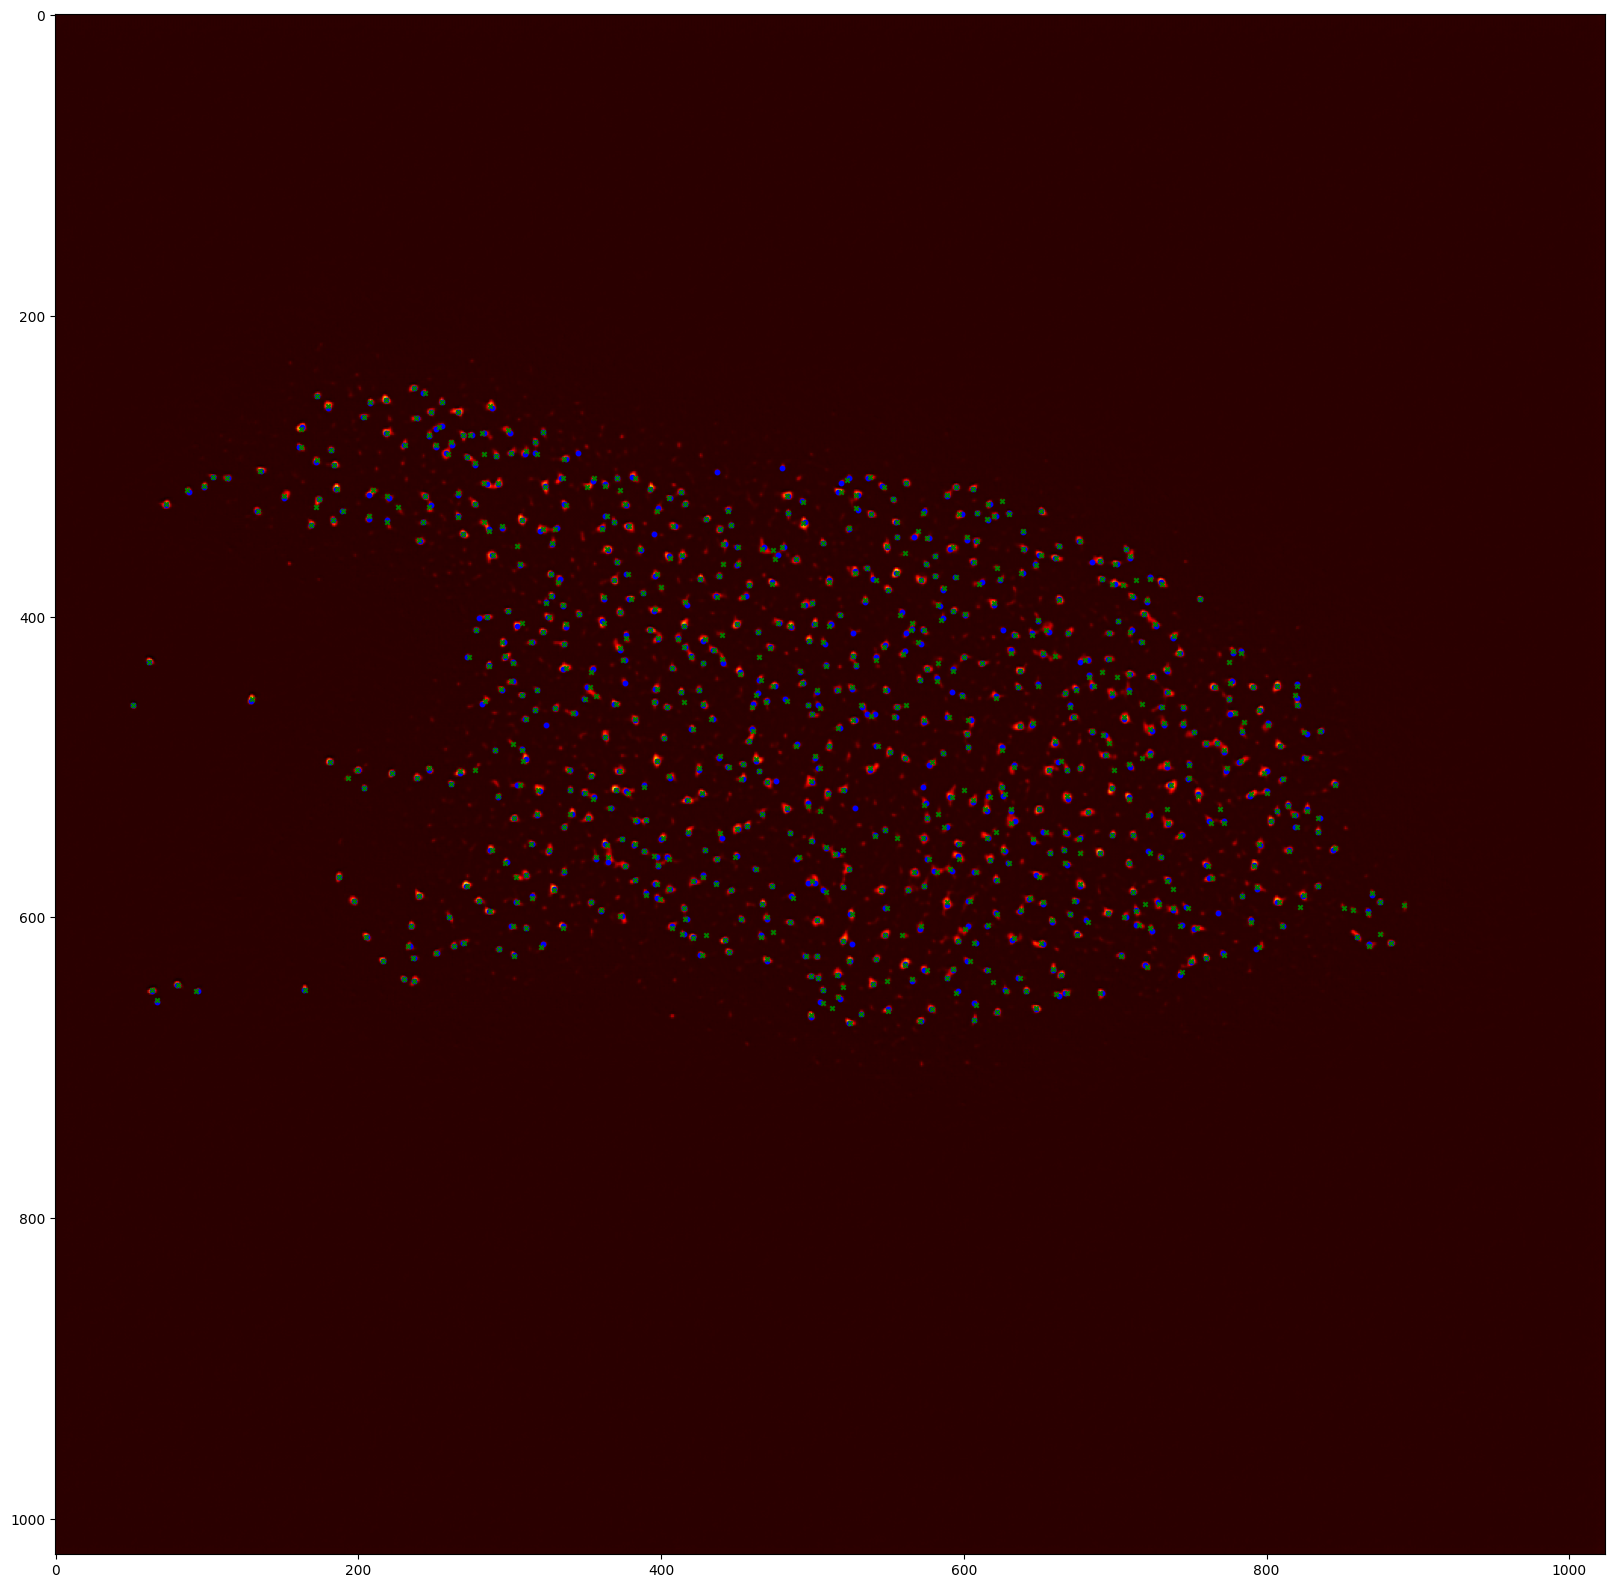

In [9]:
#peak local maxima
from skimage.feature import peak_local_max

gt=data_module.test_ds[0][1].squeeze().detach().cpu().numpy()


peaks = peak_local_max(pred_spots, min_distance=3, threshold_abs=0.25)
gt_peaks = peak_local_max(gt, min_distance=5, threshold_abs=0.10)
plt.figure(figsize=(20, 20))
plt.imshow(pred_spots, cmap='hot', aspect='auto')
plt.scatter(peaks[:, 1], peaks[:, 0], c='blue', s=10, marker='o')
plt.scatter(gt_peaks[:, 1], gt_peaks[:, 0], c='green', s=10, marker='x')
print("Number of detected peaks:", len(peaks))
print("Number of ground truth peaks:", len(gt_peaks))

In [10]:
model.eval()

all_coordinates, all_embeddings = model.predict_with_embeddings(data_module, min_distance=3, threshold_abs=0.25, disable_tqdm=False)

import pickle as pkl
# pkl.dump((all_coordinates,all_embeddings), open(f"./embeddings/spagnet_hydraflow_2.pkl", "wb"))

Predicting with min_distance=3, threshold_abs=0.25:  50%|█████     | 1/2 [00:03<00:03,  3.66s/it]

Found 738 coordinates in batch


Predicting with min_distance=3, threshold_abs=0.25: 100%|██████████| 2/2 [00:07<00:00,  3.73s/it]

Found 730 coordinates in batch


In [11]:

import numpy as np
img_0_embeddings= []
img_1_embeddings=[]
# for i in range(len(all_embeddings)-1):
for i in [0]:
    img_0_embeddings= all_embeddings[i]
    img_1_embeddings= all_embeddings[i+1]
    print(f"Image {i} has {len(img_0_embeddings)} spots, Image {i+1} has {len(img_1_embeddings)} spots")
    if len(img_0_embeddings) != len(img_1_embeddings):
        print(f"Image {i} and Image {i+1} have different number of spots: {len(img_0_embeddings)} vs {len(img_1_embeddings)}")
        # add empty embeddings to the one with less spots
        if len(img_0_embeddings) < len(img_1_embeddings):
            for _ in range(len(img_1_embeddings)-len(img_0_embeddings)):
                img_0_embeddings.append([0]*len(img_0_embeddings[0]))
        else:
            for _ in range(len(img_0_embeddings)-len(img_1_embeddings)):
                img_1_embeddings.append([0]*len(img_1_embeddings[0]))
        print (f"Image {i} and Image {i+1} have now the same number of spots: {len(img_0_embeddings)} vs {len(img_1_embeddings)}")
    #compute cosine similarity between the embeddings of the two images
    distances= np.zeros((len(img_0_embeddings), len(img_1_embeddings)))
    for j in range(len(img_0_embeddings)):
        for k in range(len(img_1_embeddings)):
            if img_0_embeddings[j] is not None and img_1_embeddings[k] is not None:
                distances[j,k]= np.linalg.norm(np.array(img_0_embeddings[j]) - np.array(img_1_embeddings[k]))
            else:
                distances[j,k]= None

Image 0 has 738 spots, Image 1 has 730 spots
Image 0 and Image 1 have different number of spots: 738 vs 730
Image 0 and Image 1 have now the same number of spots: 738 vs 738


[[ 34.37467957  28.82781982  62.66619492 ...  76.47271511  76.47271511
   76.47271511]
 [ 71.67446136  39.21692657  43.57419586 ...  87.01406988  87.01406988
   87.01406988]
 [ 40.08979034  70.98454285  96.42883301 ... 102.61052674 102.61052674
  102.61052674]
 ...
 [131.20146179  92.82978821  66.99636078 ...  89.86290211  89.86290211
   89.86290211]
 [124.41734314  77.18042755  44.72793579 ...  88.34393921  88.34393921
   88.34393921]
 [110.14305878  71.07820892  49.69454193 ...  70.95401684  70.95401684
   70.95401684]]


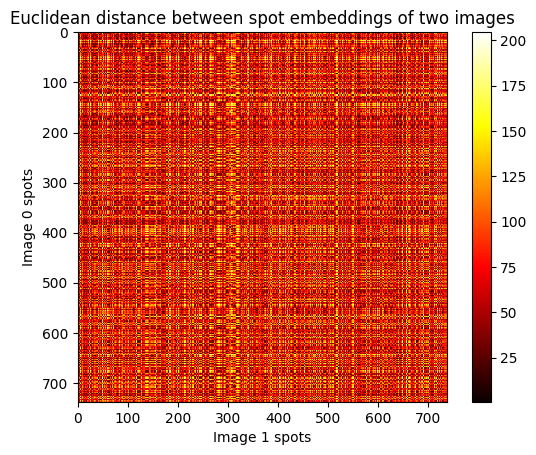

In [12]:
print(distances)
#plot as confusion matrix   
import matplotlib.pyplot as plt
plt.imshow(distances, cmap='hot', interpolation='nearest')
plt.colorbar()
plt.title("Euclidean distance between spot embeddings of two images")
plt.xlabel("Image 1 spots")
plt.ylabel("Image 0 spots")
plt.show()  

In [13]:
#optimally match the spots of the two images using the dot products as similarity scores, using the Hungarian algorithm
from scipy.optimize import linear_sum_assignment
row_ind, col_ind = linear_sum_assignment(distances) 

print("Optimal matching between spots of the two images:")
for j, k in zip(row_ind, col_ind):
    print(f"Spot {j} of image {i} is matched with spot {k} of image {i+1} with distance {distances[j,k]}")



Optimal matching between spots of the two images:
Spot 0 of image 0 is matched with spot 142 of image 1 with distance 1.5648317337036133
Spot 1 of image 0 is matched with spot 80 of image 1 with distance 3.2529048919677734
Spot 2 of image 0 is matched with spot 501 of image 1 with distance 30.139928817749023
Spot 3 of image 0 is matched with spot 167 of image 1 with distance 0.9315826296806335
Spot 4 of image 0 is matched with spot 240 of image 1 with distance 2.0921738147735596
Spot 5 of image 0 is matched with spot 249 of image 1 with distance 3.6463170051574707
Spot 6 of image 0 is matched with spot 45 of image 1 with distance 2.1288602352142334
Spot 7 of image 0 is matched with spot 260 of image 1 with distance 3.1752970218658447
Spot 8 of image 0 is matched with spot 89 of image 1 with distance 1.5270618200302124
Spot 9 of image 0 is matched with spot 241 of image 1 with distance 1.61899995803833
Spot 10 of image 0 is matched with spot 226 of image 1 with distance 1.68563508987426

(738, 2) (730, 2)
Image 0 and Image 1 have different number of spots: 738 vs 730
Adding empty coordinates to Image 1
Adding empty coordinates to Image 1
Adding empty coordinates to Image 1
Adding empty coordinates to Image 1
Adding empty coordinates to Image 1
Adding empty coordinates to Image 1
Adding empty coordinates to Image 1
Adding empty coordinates to Image 1
Image 0 and Image 1 have now the same number of spots: 738 vs 738


/tmp/ipykernel_30193/2098518260.py:22: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(coords_0[j][1], coords_0[j][0], c=color, s=10)
/tmp/ipykernel_30193/2098518260.py:26: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(coords_1_matched[j][1], coords_1_matched[j][0], c=color, marker='x')


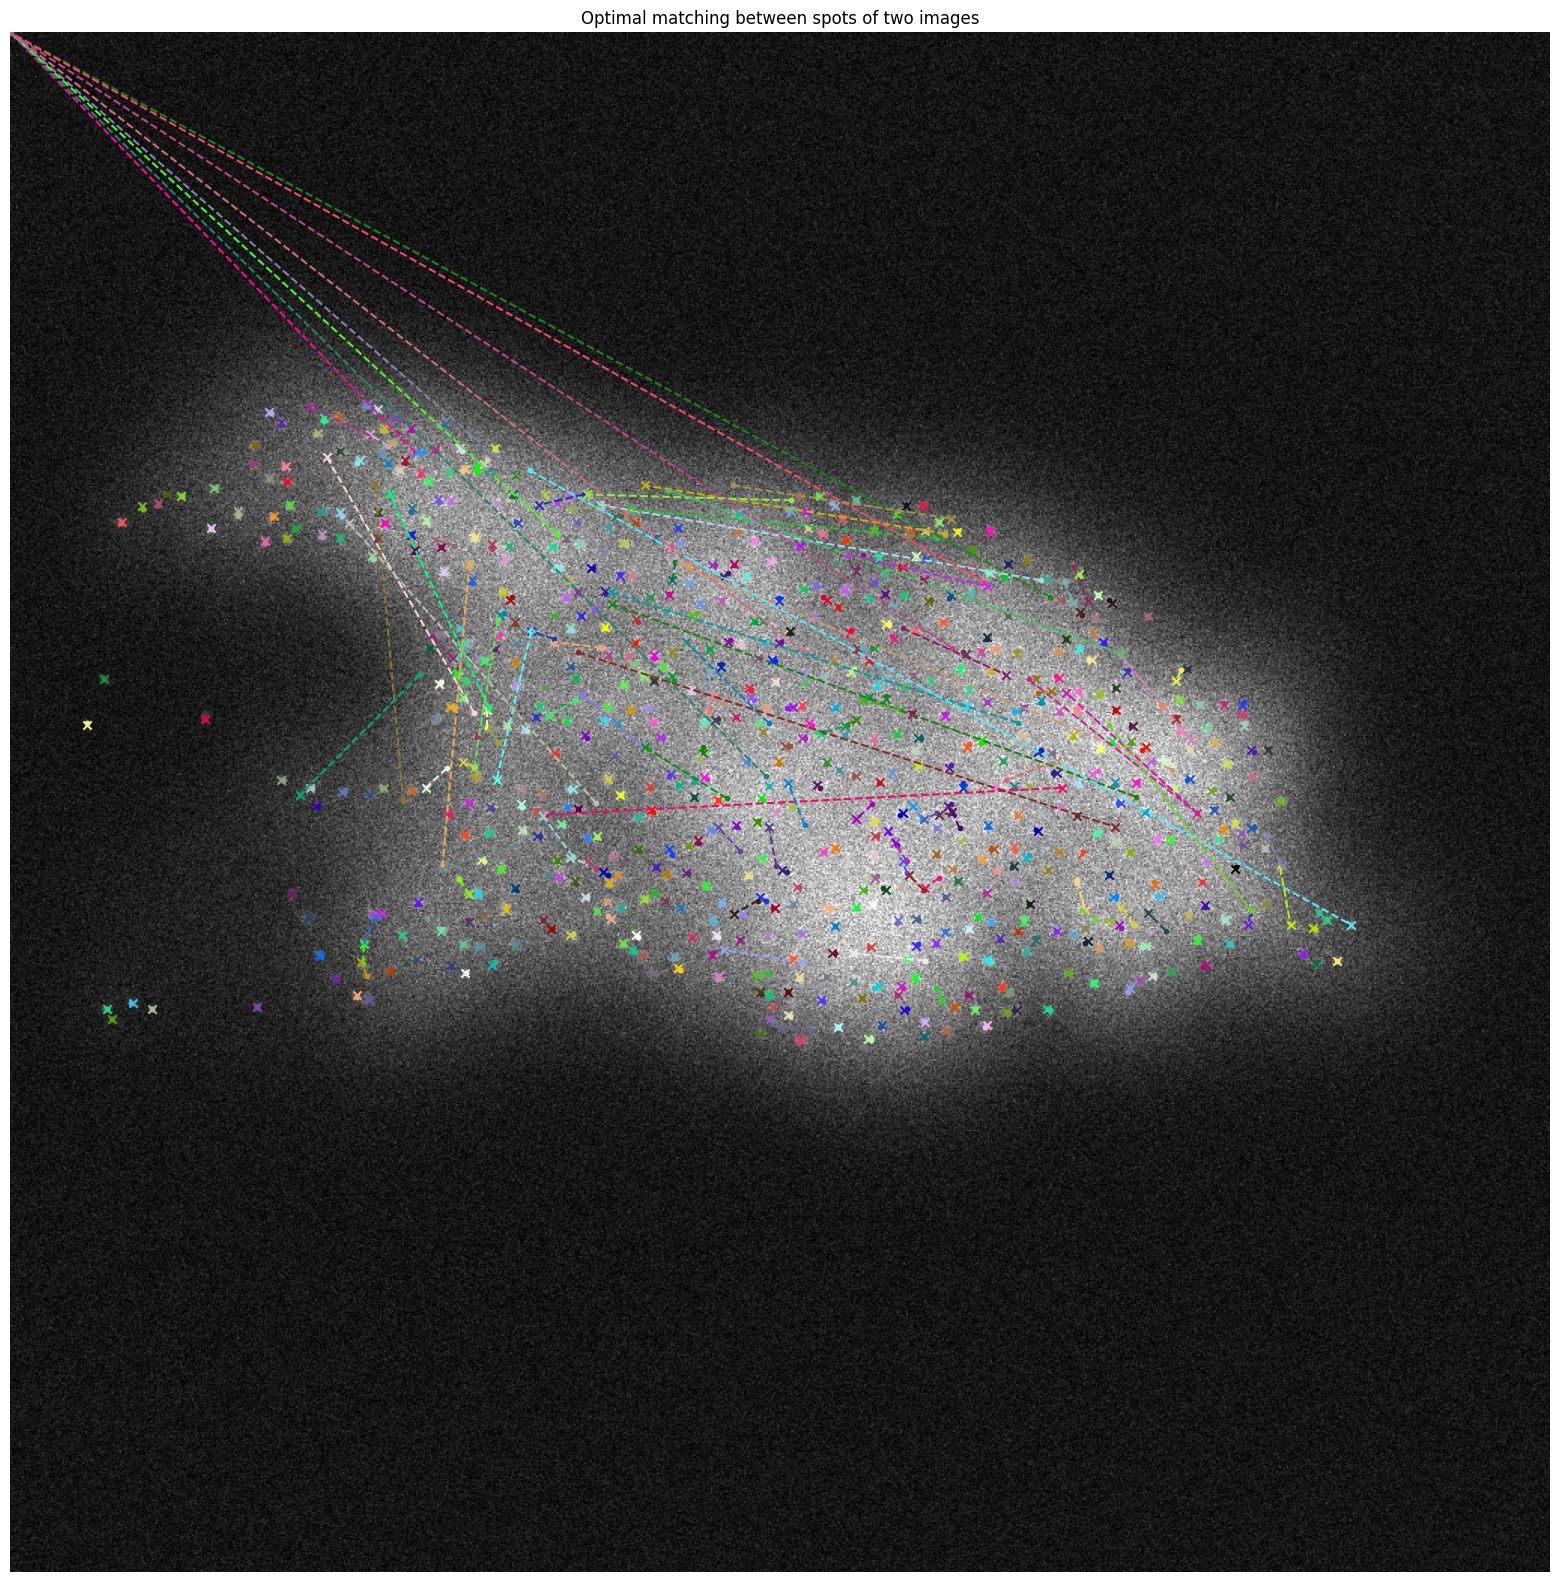

In [14]:
img_0=data_module.test_ds.images[0]
coords_0= all_coordinates[0]
coords_1= all_coordinates[1]
print(coords_0.shape, coords_1.shape)
if len(coords_0) != len(coords_1):
    print(f"Image 0 and Image 1 have different number of spots: {len(coords_0)} vs {len(coords_1)}")
    if len(coords_0) < len(coords_1):
        for _ in range(len(coords_1)-len(coords_0)):
            coords_0= np.vstack([coords_0, [0,0]])
    else:
        for _ in range(len(coords_0)-len(coords_1)):
            print("Adding empty coordinates to Image 1")
            coords_1= np.vstack([coords_1, [0,0]])
coords_1_matched= [coords_1[k] for k in col_ind]
print(f"Image 0 and Image 1 have now the same number of spots: {len(coords_0)} vs {len(coords_1)}")
#plot the two images side by side with the spots and the optimal matching between them
plt.figure(figsize=(20,20))
plt.imshow(img_0, cmap='gray')

for j in range(len(coords_0)):
    color= np.random.rand(3,)
    plt.scatter(coords_0[j][1], coords_0[j][0], c=color, s=10)
    #write id of the spot next to the spot in the image
    # for k in range(len(coords_0)):
    #     plt.text(coords_0[k][1]+1, coords_0[k][0]+1, str(k), color="white", fontsize=12)
    plt.scatter(coords_1_matched[j][1], coords_1_matched[j][0], c=color, marker='x')
    # for j in range(len(coords_0)):
    #     plt.text(coords_1_matched[j][1]-3, coords_1_matched[j][0]-3, str(j), color="yellow", fontsize=12)
    plt.plot([coords_0[j][1], coords_1_matched[j][1]], [coords_0[j][0], coords_1_matched[j][0]], c=color, linestyle='--')
plt.title("Optimal matching between spots of two images")
plt.axis('off')
plt.show()

1476 (1476, 64)


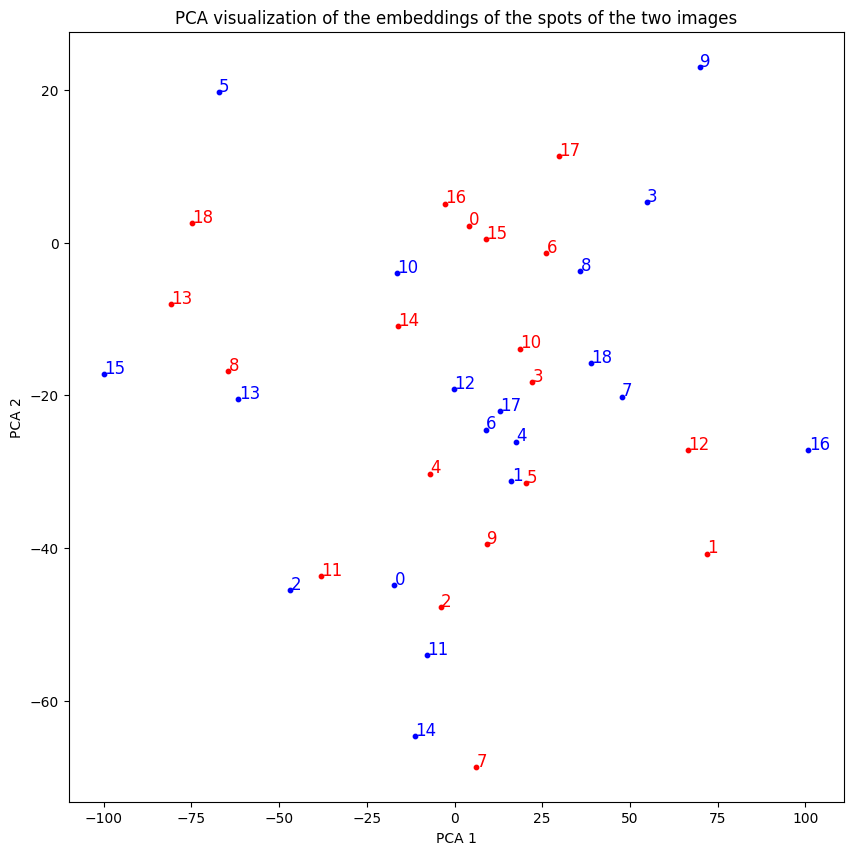

In [15]:
# pca visualization of the embeddings of the spots of the two images
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
all_embeddings_flat= []
all_embeddings_flat= np.concatenate([np.array(img_0_embeddings), np.array(img_1_embeddings)], axis=0)
all_embeddings_flat= np.array(all_embeddings_flat)
print(len(all_embeddings_flat), all_embeddings_flat.shape)
pca_result = pca.fit_transform(all_embeddings_flat)
plt.figure(figsize=(10,10))
plt.scatter(pca_result[:19,0], pca_result[:19,1], c='blue', s=10, marker='o')
for i in range(19):
    plt.text(pca_result[i,0]+0.1, pca_result[i,1]+0.1, str(i), color="blue", fontsize=12)
plt.scatter(pca_result[19:38,0], pca_result[19:38,1], c='red', s=10, marker='o')
for i in range(19, 38):
    plt.text(pca_result[i,0]+0.1, pca_result[i,1]+0.1, str(i-19), color="red", fontsize=12)
plt.title("PCA visualization of the embeddings of the spots of the two images")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.show()


In [18]:
import torch
import torch.nn.functional as F

def pool_and_broadcast_differentiable(dense_features, instance_mask):
    """
    A fast, fully differentiable (w.r.t dense_features) implementation 
    using matrix multiplication instead of for-loops.
    """
    C, H, W = dense_features.shape
    
    # 1. Flatten spatial dimensions
    # dense_features: (C, H*W)
    # instance_mask: (H*W,)
    feat_flat = dense_features.view(C, H * W) 
    mask_flat = instance_mask.view(H * W)     
    
    # Find the maximum ID to determine number of distinct instances
    # (Assumes masks are sequentially numbered 0, 1, 2... K)
    num_instances = int(mask_flat.max().item()) + 1
    
    # 2. Create one-hot encoded masks
    # Shape: (H*W, num_instances)
    one_hot = F.one_hot(mask_flat, num_classes=num_instances).to(feat_flat.dtype)
    
    # 3. Sum features for each cell via Matrix Multiplication
    # (C, H*W) @ (H*W, num_instances) -> (C, num_instances)
    cell_sums = feat_flat @ one_hot
    
    # 4. Count pixels per cell to calculate the mean
    # Shape: (num_instances,)
    cell_counts = one_hot.sum(dim=0)
    
    # Compute mean (add a tiny epsilon to prevent division by zero)
    # Shape: (C, num_instances)
    cell_means = cell_sums / (cell_counts + 1e-8)
    
    # (Optional) If you want the background (ID=0) to remain zeros
    # cell_means[:, 0] = 0 
    
    # 5. Broadcast back to pixels via Matrix Multiplication
    # (C, num_instances) @ (num_instances, H*W) -> (C, H*W)
    uniform_flat = cell_means @ one_hot.T
    
    # 6. Reshape back to original image dimensions
    return uniform_flat.view(C, H, W)

In [19]:
H, W = 256, 256
# Mock feature map from a CNN (64 channels)
features = torch.randn(64, H, W) 

# Mock instance mask (0=bg, 1=cell_1, 2=cell_2)
mask = torch.zeros(H, W, dtype=torch.long)
mask[10:50, 10:50] = 1   # Cell 1 footprint
mask[100:150, 100:150] = 2 # Cell 2 footprint

output = pool_and_broadcast_differentiable(features, mask)

# Verification: check if two pixels in Cell 1 have the exact same feature
pixel_a = output[:, 15, 15]
pixel_b = output[:, 45, 45]
print("Features identical?", torch.allclose(pixel_a, pixel_b)) # Returns True

Features identical? True
